# 06 · Model Comparison & Selection - MEPS HC-243 (2022)

**Goal:** put the best variant of every algorithm (chosen in notebook 05) through **exactly the same test**, compare them on every metric, check whether the differences are real or just noise, and pick a **shortlist** for hyperparameter tuning in notebook 07.

| Step | What happens | Main library |
|---|---|---|
| 1-2 | Rebuild the 9 winning models and score them on the same 5 folds | scikit-learn, xgboost |
| 3-4 | Comparison table and metric charts | pandas, Seaborn |
| 5 | Fold-to-fold stability | Seaborn |
| 6-7 | ROC and Precision-Recall curves for all models | scikit-learn displays |
| 8 | Confusion matrices for all models | scikit-learn |
| 9-10 | Overfitting check, and speed vs accuracy | Matplotlib |
| 11 | Are the differences statistically real? | SciPy |
| 12 | Learning curves: would more data help? | scikit-learn |
| 13 | Decision: the shortlist | JSON |

> Still **training data only**. The test set is opened once, in notebook 07, after tuning.

## Step 0 - Setup

**🛠️ What this code does:** Imports the libraries:
- **scikit-learn** for models, metrics, curve displays and `learning_curve`.
- **SciPy** for the statistical test.
- **pandas, NumPy, Matplotlib, Seaborn** for tables and charts.
- The project modules: `classification.py` rebuilds each winning variant by name, and `evaluation.py` runs cross-validation.

In [1]:
import sys, json, time, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from IPython.display import display
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay, f1_score
from sklearn.model_selection import learning_curve

from src.preprocessing import (load_split, load_selected_features, build_preprocessor, cv_folds,
                               LABEL_COL, GROUP_COL, RANDOM_STATE)
from src.classification import ALGORITHMS, build, make_pipeline, load_best_variants
from src.evaluation import evaluate_cv, summarize, METRIC_LABELS
from src.visualization import (SERIES, LOW_COST_COLOR, HIGH_COST_COLOR, INK, INK_SECONDARY, INK_MUTED, SURFACE,
                               SEQUENTIAL_BLUE, apply_style, save_fig, model_color)

apply_style()
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 50)
RESULTS = ROOT / "reports" / "results"
print("Libraries loaded.")

Libraries loaded.


## Step 1 - Load the data and the winning variants

**🛠️ What this code does:** Loads the training data, recreates the same 5 folds and preprocessing, and reads `best_variants.json` (written by notebook 05), which records the best variant of each algorithm.

In [2]:
train, _ = load_split()
features = load_selected_features()
X, y, groups = train[features], train[LABEL_COL], train[GROUP_COL]
folds = cv_folds(X, y, groups)
preprocessor = build_preprocessor(features)
pos_weight = float((y == 0).sum() / (y == 1).sum())

best = load_best_variants()
display(pd.DataFrame({"chosen variant": best}).rename_axis("algorithm"))

,chosen variant
algorithm,
Logistic Regression,L2 + balanced
KNN,"k=75, uniform, euclidean"
Decision Tree,"Entropy, max_depth=6"
Random Forest,"300 trees, min_samples_leaf=5"
SVM,Linear kernel
Naive Bayes,"Bernoulli NB, equal priors"
Gradient Boosting,HistGradientBoosting + balanced
XGBoost,"scale_pos_weight, depth 3, 600 trees"
Voting,Soft voting (LR + RF + XGB)


**📖 What the result shows:**
These are the 9 models that go head to head, one per algorithm. Each is the variant with the best cross-validated ROC-AUC in notebook 05.

## Step 2 - Score every model on the same folds

> **🎓 Theory in brief**
>
> A fair comparison means **the same data, the same folds, the same preprocessing and the same metrics** for every model. Any difference in score can then only come from the algorithm itself, plus random noise, which Step 11 measures.
>
> *More detail: [Theory notes](../docs/THEORY_NOTES.md#13-comparing-and-selecting-models)*

**🛠️ What this code does:** Trains each of the 9 models (plus the "always low cost" dummy as a reference) on the 5 folds, with preprocessing inside every fold. It keeps validation and training scores and every person's out-of-fold prediction. The SVM now trains on **all** 17,398 people rather than the 5,000-person subsample, so it is the slowest step.

In [3]:
PARALLEL_FOLDS = {"Logistic Regression", "KNN", "Decision Tree", "SVM", "Naive Bayes", "Gradient Boosting"}
results = {}
model, sampler = build("Baseline", "Dummy (most frequent)", pos_weight)
results["Dummy"] = evaluate_cv(make_pipeline(preprocessor, model, sampler), X, y, folds, n_jobs=5)
for algo in ALGORITHMS:
    model, sampler = build(algo, best[algo], pos_weight)
    t0 = time.perf_counter()
    results[algo] = evaluate_cv(make_pipeline(preprocessor, model, sampler), X, y, folds,
                                n_jobs=5 if algo in PARALLEL_FOLDS else None)
    print(f"{algo:<20} {best[algo]:<40} {time.perf_counter() - t0:6.1f} s")

Logistic Regression  L2 + balanced                               1.4 s


KNN                  k=75, uniform, euclidean                   14.9 s


Decision Tree        Entropy, max_depth=6                        1.3 s


Random Forest        300 trees, min_samples_leaf=5              14.8 s


SVM                  Linear kernel                              99.6 s


Naive Bayes          Bernoulli NB, equal priors                  1.1 s


Gradient Boosting    HistGradientBoosting + balanced             5.6 s


XGBoost              scale_pos_weight, depth 3, 600 trees       13.2 s


Voting               Soft voting (LR + RF + XGB)                24.5 s


**📖 What the result shows:**
All models are trained. Most finish in seconds; the full-data SVM takes longest, because kernel SVMs scale poorly with the number of rows.

## Step 3 - The comparison table

**🛠️ What this code does:** Builds the comparison table from the project plan (accuracy, precision, recall, F1, ROC-AUC), adds PR-AUC, balanced accuracy and training time, sorts by ROC-AUC, and saves it to `reports/results/model_comparison.csv`.

In [4]:
summary = summarize(results).astype(float)
table = summary[["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "balanced_accuracy",
                 "roc_auc_std", "train_roc_auc", "fit_time_s"]].sort_values("roc_auc", ascending=False)
table.insert(0, "variant", [best.get(m, "always predicts low cost") for m in table.index])
table.round(4).to_csv(RESULTS / "model_comparison.csv")
display(table.round(3).rename(columns={**METRIC_LABELS, "roc_auc_std": "ROC-AUC std", "train_roc_auc": "Train ROC-AUC",
                                       "fit_time_s": "Fit time (s)"}))

,variant,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Balanced accuracy,ROC-AUC std,Train ROC-AUC,Fit time (s)
Voting,Soft voting (LR + RF + XGB),0.772,0.455,0.703,0.552,0.826,0.568,0.746,0.004,0.892,3.460
XGBoost,"scale_pos_weight, depth 3, 600 trees",0.756,0.435,0.733,0.546,0.824,0.565,0.747,0.003,0.874,2.095
Logistic Regression,L2 + balanced,0.756,0.434,0.724,0.543,0.822,0.566,0.744,0.004,0.828,0.579
Gradient Boosting,HistGradientBoosting + balanced,0.752,0.430,0.731,0.542,0.821,0.561,0.744,0.005,0.877,3.804
SVM,Linear kernel,0.765,0.445,0.706,0.546,0.821,0.562,0.743,0.006,0.826,52.241
Random Forest,"300 trees, min_samples_leaf=5",0.788,0.478,0.646,0.550,0.821,0.553,0.735,0.004,0.933,1.831
KNN,"k=75, uniform, euclidean",0.827,0.695,0.243,0.359,0.811,0.539,0.608,0.004,0.828,0.189
Naive Bayes,"Bernoulli NB, equal priors",0.699,0.376,0.763,0.503,0.800,0.531,0.723,0.003,0.800,0.212
Decision Tree,"Entropy, max_depth=6",0.719,0.395,0.726,0.509,0.792,0.487,0.722,0.005,0.820,0.400
Dummy,always predicts low cost,0.800,0.000,0.000,0.000,0.500,0.200,0.500,0.000,0.500,0.375


**📖 What the result shows:**
This is the project plan's comparison table, with every model scored the same way (5-fold CV on the 17,398 training people):

| Rank | Model | ROC-AUC | PR-AUC | F1 | Recall | Precision |
|---|---|---|---|---|---|---|
| 1 | **Voting** (soft: LR + RF + XGB) | **0.826** | **0.568** | **0.552** | 0.703 | 0.455 |
| 2 | **XGBoost** | 0.824 | 0.565 | 0.546 | 0.733 | 0.435 |
| 3 | **Logistic Regression** | 0.822 | 0.566 | 0.543 | 0.724 | 0.434 |
| 4-6 | Gradient Boosting / SVM / Random Forest | 0.821 | 0.553-0.562 | 0.542-0.550 | 0.646-0.731 | 0.430-0.478 |
| 7 | KNN | 0.811 | 0.539 | 0.359 | 0.243 | 0.695 |
| 8 | Naive Bayes | 0.800 | 0.531 | 0.503 | 0.763 | 0.376 |
| 9 | Decision Tree | 0.792 | 0.487 | 0.509 | 0.726 | 0.395 |
| | *Dummy (always low cost)* | *0.500* | *0.200* | *0.000* | *0.000* | *-* |

- The **top six models are within 0.005 ROC-AUC** of each other.
- On full data the **SVM falls to 0.821**. Its 0.833 in notebook 05 came from the smaller subsample.
- **KNN has the highest accuracy (0.827)** but the lowest F1, because it flags very few people (recall 0.24). Accuracy rewards ignoring the minority class.

## Step 4 - Metric by metric

**🛠️ What this code does:** Draws one panel per metric with one bar per model, sorted by ROC-AUC in every panel so each model stays in the same row. The dashed line marks the "always low cost" dummy.

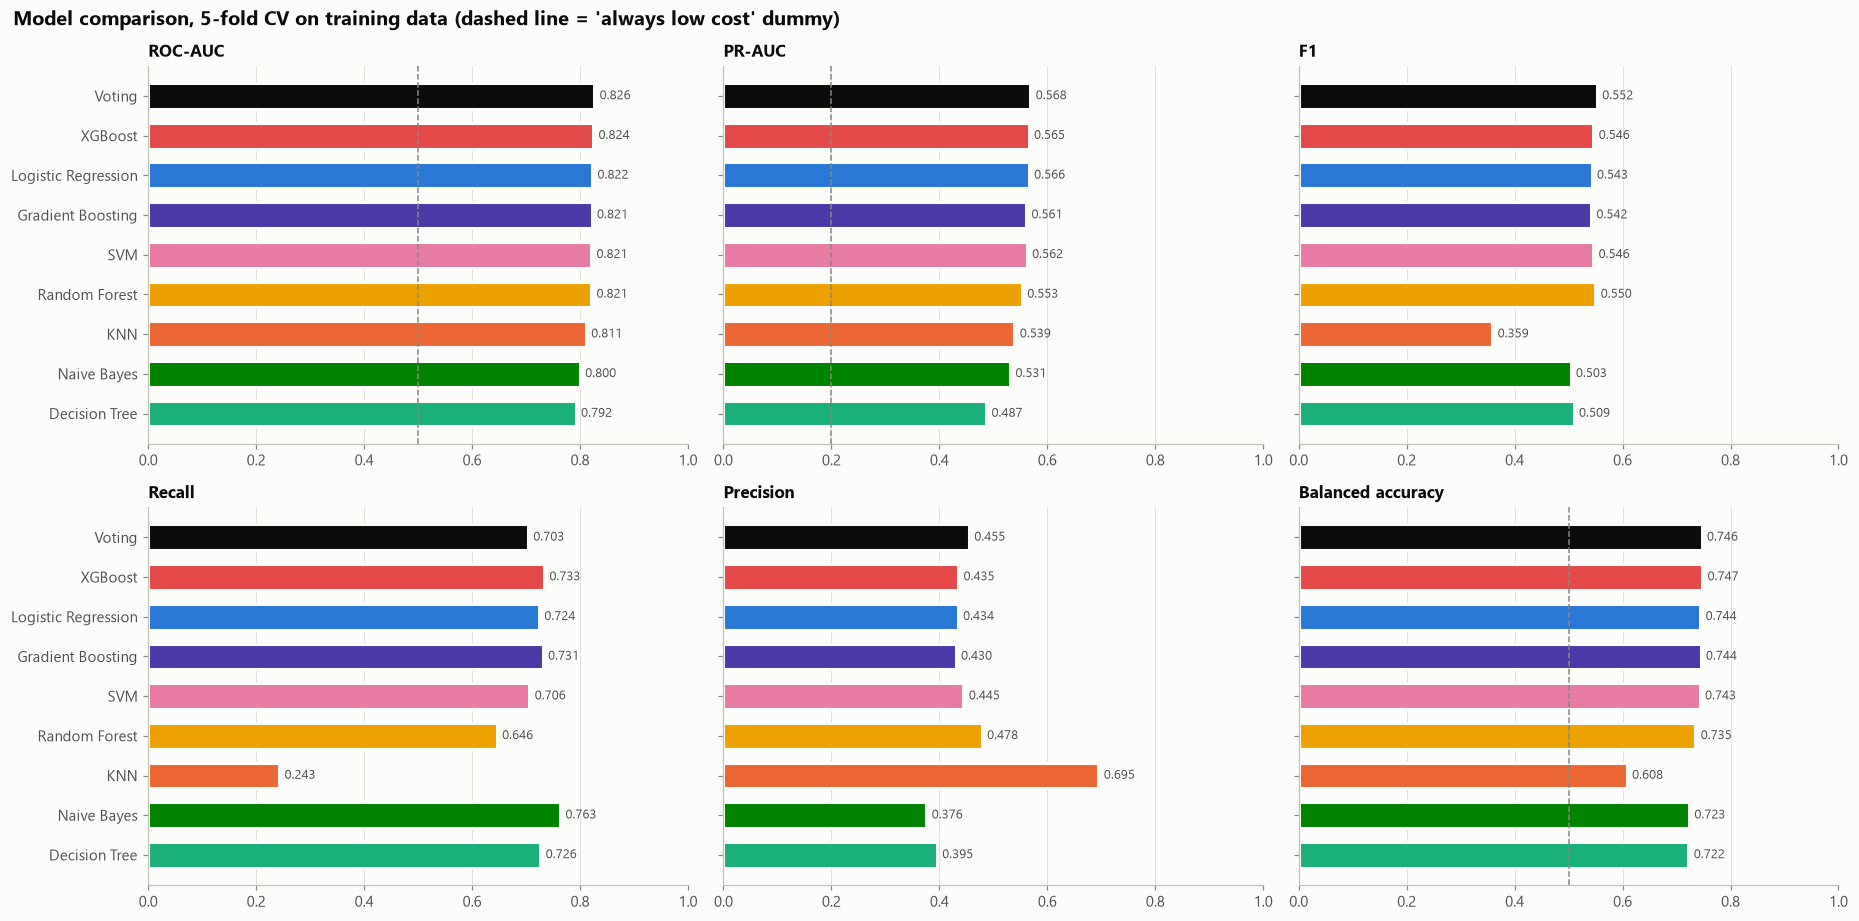

In [5]:
models = [m for m in table.index if m != "Dummy"]
panels = ["roc_auc", "pr_auc", "f1", "recall", "precision", "balanced_accuracy"]
fig, axes = plt.subplots(2, 3, figsize=(17, 8.5), sharey=True)
for ax, m in zip(axes.ravel(), panels):
    vals = table.loc[models, m]
    ax.barh(models, vals, color=[model_color(n) for n in models], height=0.65, edgecolor=SURFACE, linewidth=2)
    for i, v in enumerate(vals):
        ax.text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=8.5, color=INK_SECONDARY)
    ax.axvline(table.loc["Dummy", m], color=INK_MUTED, linestyle="--", linewidth=1)
    ax.set_xlim(0, 1.0)
    ax.grid(axis="y", visible=False)
    ax.set_title(METRIC_LABELS[m], fontsize=11)
axes[0, 0].invert_yaxis()          # shared y-axis: flip once so the best model is on top
fig.suptitle("Model comparison, 5-fold CV on training data (dashed line = 'always low cost' dummy)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "06_metric_comparison")
plt.show()

#### 📖 What this chart shows (in plain English)
Each panel is one metric, with models in the same order (best ROC-AUC on top).

- **ROC-AUC and PR-AUC:** the bars of the top six are practically the same length. Only KNN, Naive Bayes and the single tree are visibly shorter.
- **Recall vs precision:** this is where the models really differ, because each one sits at a different point of the trade-off at its default threshold.
  - **KNN:** low recall (0.24), high precision (0.70); it has no class weighting.
  - **Naive Bayes:** the opposite, high recall (0.76) and low precision (0.38).
  - **Random forest:** in between (0.65 / 0.48).
- **F1** balances the two, and the top six all land at 0.54-0.55.

Since these threshold metrics can be adjusted by moving the threshold, **ROC-AUC and PR-AUC are the fairer basis for choosing an algorithm**.

## Step 5 - How stable is each model across folds?

**🛠️ What this code does:** Plots the 5 individual fold scores (dots) and their spread (box) for each model's ROC-AUC. If the boxes of two models overlap heavily, their average difference may be just luck.

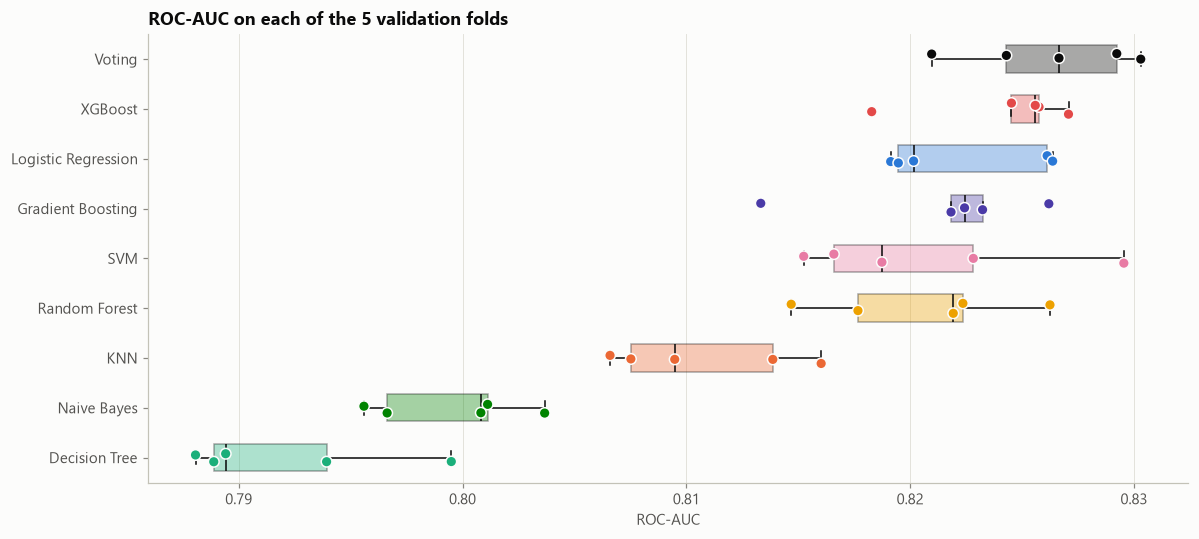

In [6]:
folds_long = pd.DataFrame([{"model": m, "fold": i + 1, "ROC-AUC": v}
                           for m in models for i, v in enumerate(results[m].folds["test_roc_auc"])])
fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=folds_long, y="model", x="ROC-AUC", order=models, hue="model", palette={m: model_color(m) for m in models},
            saturation=1, width=0.55, boxprops={"alpha": 0.35}, showfliers=False, legend=False, ax=ax)
sns.stripplot(data=folds_long, y="model", x="ROC-AUC", order=models, hue="model",
              palette={m: model_color(m) for m in models}, size=7, edgecolor=SURFACE, linewidth=1, jitter=0.12,
              legend=False, ax=ax)
ax.set_ylabel("")
ax.grid(axis="y", visible=False)
ax.set_title("ROC-AUC on each of the 5 validation folds")
fig.tight_layout()
save_fig(fig, "06_fold_variability")
plt.show()

#### 📖 What this chart shows (in plain English)
Each dot is one fold's ROC-AUC, and each box spans the middle three folds.

- The boxes of **Voting, XGBoost, logistic regression, Gradient Boosting, SVM and random forest overlap heavily**, all between about 0.815 and 0.83. The score of a given model moves by about ±0.005 just depending on *which people* land in the validation fold.
- **KNN, Naive Bayes and the decision tree** sit clearly to the left. Their gap is real, not luck.
- XGBoost and Gradient Boosting are the most consistent (narrow boxes). SVM is the most variable.

## Step 6 - ROC curves for all models

**🛠️ What this code does:** Draws every model's ROC curve from its out-of-fold predictions. The right panel zooms into the middle of the curve, where the lines are hardest to tell apart.

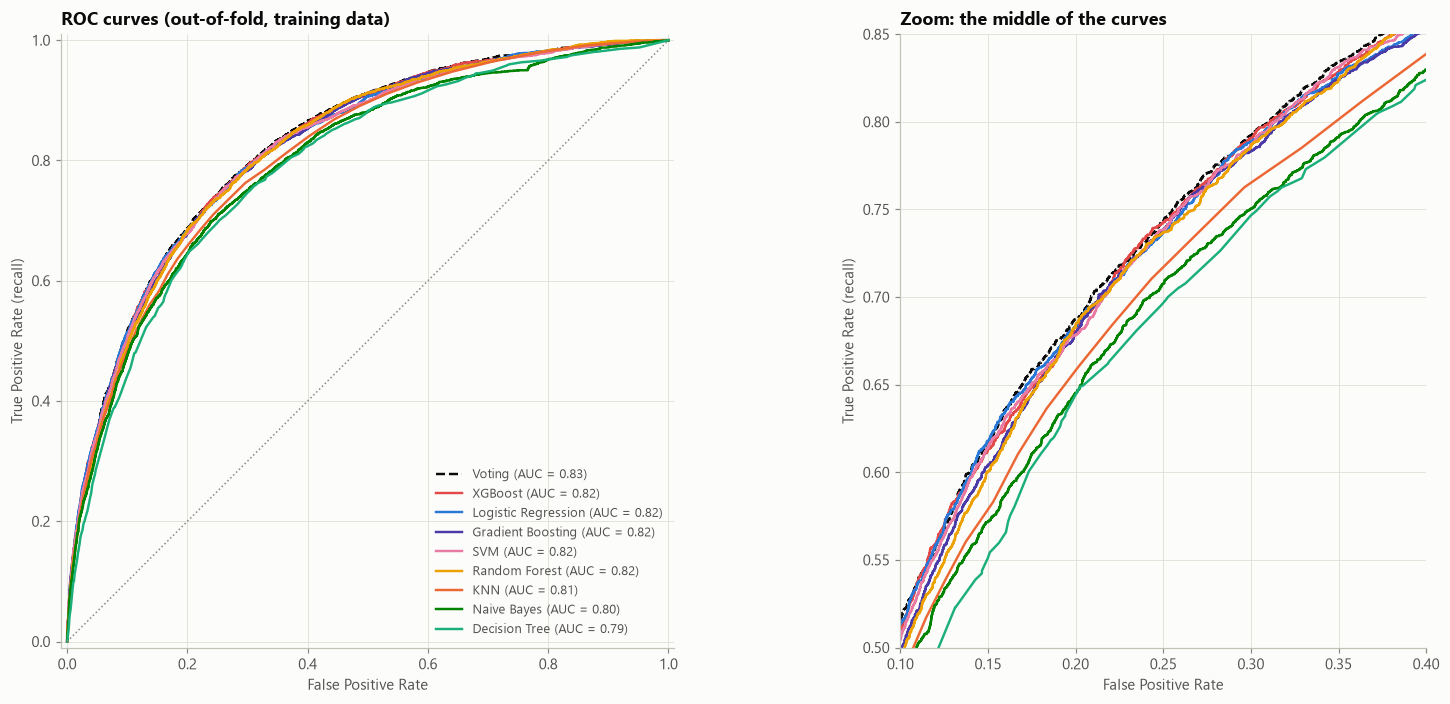

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, zoom in zip(axes, [False, True]):
    for m in models:
        RocCurveDisplay.from_predictions(y, results[m].oof_scores, name=m, ax=ax,
                                         curve_kwargs={"color": model_color(m), "linewidth": 1.6,
                                                       "linestyle": "--" if m == "Voting" else "-"})
    ax.plot([0, 1], [0, 1], color=INK_MUTED, linestyle=":", linewidth=1)
    if zoom:
        ax.set_xlim(0.1, 0.4); ax.set_ylim(0.5, 0.85)
        ax.set_title("Zoom: the middle of the curves")
        ax.get_legend().remove()
    else:
        ax.set_title("ROC curves (out-of-fold, training data)")
        ax.legend(fontsize=8.5, loc="lower right")
    ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate (recall)")
fig.tight_layout()
save_fig(fig, "06_roc_curves")
plt.show()

#### 📖 What this chart shows (in plain English)
**Left:** all nine ROC curves bunch together far above the diagonal. **Right (zoom):** the top six curves are almost indistinguishable. KNN (orange), Naive Bayes (green) and the decision tree (aqua) run visibly lower, so at any false-alarm rate they catch fewer high-cost people.

At a 20% false-positive rate, for example, the top models catch about **69%** of high-cost people and the decision tree about **65%**.

## Step 7 - Precision-Recall curves for all models

**🛠️ What this code does:** Draws every model's precision-recall curve from its out-of-fold predictions, with the 0.20 no-skill line.

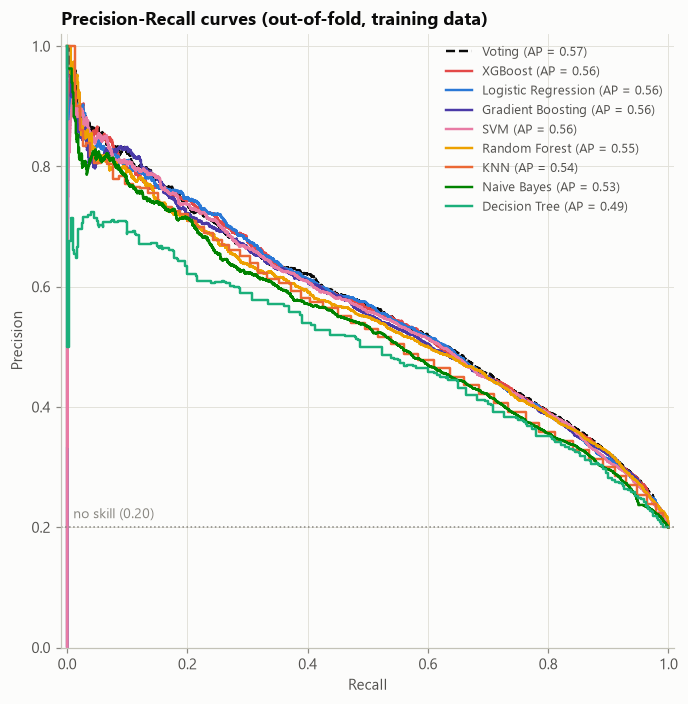

In [8]:
fig, ax = plt.subplots(figsize=(10, 6.5))
for m in models:
    PrecisionRecallDisplay.from_predictions(y, results[m].oof_scores, name=m, ax=ax,
                                            curve_kwargs={"color": model_color(m), "linewidth": 1.6,
                                                          "linestyle": "--" if m == "Voting" else "-"})
ax.axhline(y.mean(), color=INK_MUTED, linestyle=":", linewidth=1)
ax.text(0.01, y.mean() + 0.015, "no skill (0.20)", fontsize=9, color=INK_MUTED)
ax.set_ylim(0, 1.02)
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.legend(fontsize=8.5, loc="upper right")
ax.set_title("Precision-Recall curves (out-of-fold, training data)")
fig.tight_layout()
save_fig(fig, "06_precision_recall_curves")
plt.show()

#### 📖 What this chart shows (in plain English)
- The top six curves overlap along their whole length, with AP 0.55-0.57.
- **The decision tree (aqua)** is clearly lowest on the left. Its most confident predictions are only about 70% precise, against 80-90% for the others, because a depth-6 tree gives the same score to everyone in a leaf, so it can't rank people finely.
- **Naive Bayes and KNN** drop below the top group in the middle range.
- Every curve ends at precision 0.20 (the base rate) when recall reaches 1.

## Step 8 - Confusion matrices for all models

**🛠️ What this code does:** Draws a confusion matrix for each model at its default threshold, as a percentage of each true class. The top-left cell is low-cost people correctly left alone (specificity), and the bottom-right is high-cost people caught (recall).

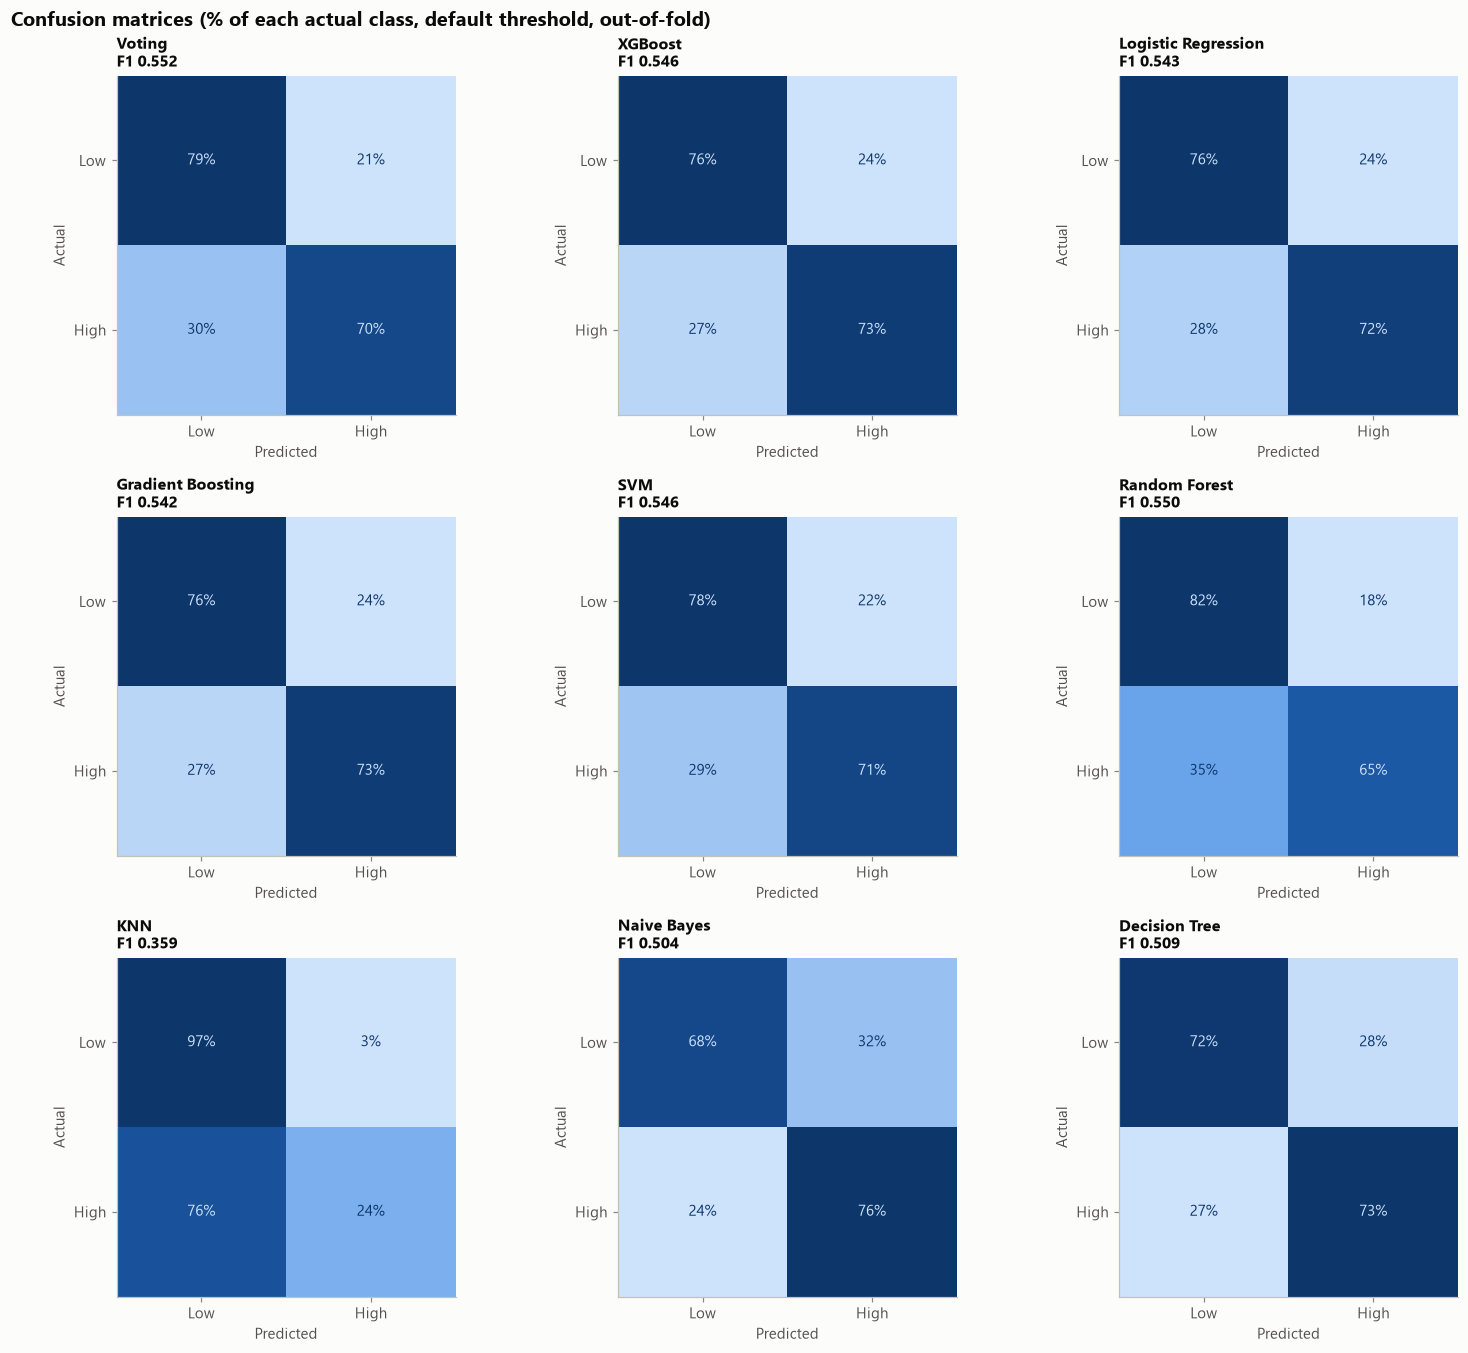

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(14, 12.5))
for ax, m in zip(axes.ravel(), models):
    ConfusionMatrixDisplay.from_predictions(y, results[m].oof_pred, display_labels=["Low", "High"], normalize="true",
                                            values_format=".0%", cmap=SEQUENTIAL_BLUE, colorbar=False, ax=ax)
    ax.set_title(f"{m}\nF1 {f1_score(y, results[m].oof_pred):.3f}", fontsize=10.5)
    ax.grid(False)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
fig.suptitle("Confusion matrices (% of each actual class, default threshold, out-of-fold)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "06_confusion_matrices")
plt.show()

#### 📖 What this chart shows (in plain English)
Each matrix shows the share of each *actual* class. Top-left is low-cost people correctly left alone; bottom-right is high-cost people caught.

- **Top six:** catch **65-73%** of high-cost people and correctly leave **76-82%** of low-cost people alone. Random forest is a little more cautious (catches 65%, false alarms on 18%); XGBoost and Gradient Boosting are a little more eager (73% / 24%).
- **KNN:** leaves 97% of low-cost people alone, but **misses 76% of high-cost people**.
- **Naive Bayes:** catches 76% of high-cost people, but raises **false alarms on 32%** of low-cost people.

These differences are mostly about *where the default threshold falls* for each model, not about ranking skill.

## Step 9 - Overfitting: training vs validation ROC-AUC

> **🎓 Theory in brief**
>
> The gap between training and validation scores shows how much a model **memorised** rather than learned. A small gap is good. A large gap means the model would gain from more regularisation (shallower trees, larger leaves, a stronger penalty), which tuning in notebook 07 can test.
>
> *More detail: [Theory notes](../docs/THEORY_NOTES.md#11-overfitting-underfitting-and-the-bias-variance-trade-off)*

**🛠️ What this code does:** Draws a dumbbell for each model: the grey dot is the training ROC-AUC, the coloured dot is the validation ROC-AUC, and the line between them is the overfitting gap.

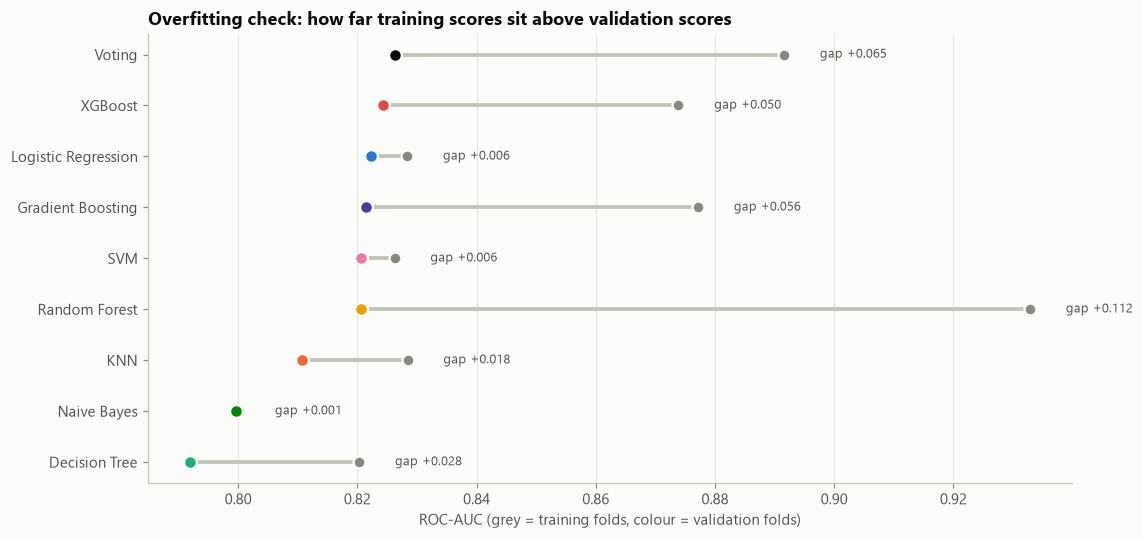

In [10]:
gap = table.loc[models, ["train_roc_auc", "roc_auc"]].assign(gap=lambda d: d.train_roc_auc - d.roc_auc)
fig, ax = plt.subplots(figsize=(10.5, 5))
for i, (m, r) in enumerate(gap.iterrows()):
    ax.plot([r.roc_auc, r.train_roc_auc], [i, i], color="#c3c2b7", linewidth=2.5, zorder=1)
    ax.scatter(r.train_roc_auc, i, color=INK_MUTED, s=60, zorder=2, edgecolor=SURFACE, linewidth=1.5)
    ax.scatter(r.roc_auc, i, color=model_color(m), s=70, zorder=3, edgecolor=SURFACE, linewidth=1.5)
    ax.text(max(r.train_roc_auc, r.roc_auc) + 0.006, i, f"gap {r.gap:+.3f}", va="center", fontsize=8.5,
            color=INK_SECONDARY)
ax.set_yticks(range(len(gap)), gap.index)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("ROC-AUC (grey = training folds, colour = validation folds)")
ax.set_title("Overfitting check: how far training scores sit above validation scores")
fig.tight_layout()
save_fig(fig, "06_overfitting_gap")
plt.show()

#### 📖 What this chart shows (in plain English)
The grey dot is the training score, the coloured dot the validation score, and the line between them is the overfitting gap.

- **Smallest gaps:** Naive Bayes (+0.001), logistic regression (+0.006), linear SVM (+0.006). Simple models can't memorise.
- **Biggest gap:** random forest (**+0.112**). Its trees grow until only 5 people remain per leaf, so it almost memorises the training data, yet its validation score is still competitive (0.821), because averaging protects it.
- **Boosting and voting:** gaps of +0.050 to +0.065, a moderate amount of memorisation.
- **Tuning target for notebook 07:** XGBoost and the forest inside the voting model have room for more regularisation (shallower trees, larger leaves, fewer rounds). That might close the gap without losing validation skill.

## Step 10 - Skill vs training time

**🛠️ What this code does:** Plots each model's validation ROC-AUC against the seconds needed to train it once (log scale). Models in the top-left corner are both accurate and fast.

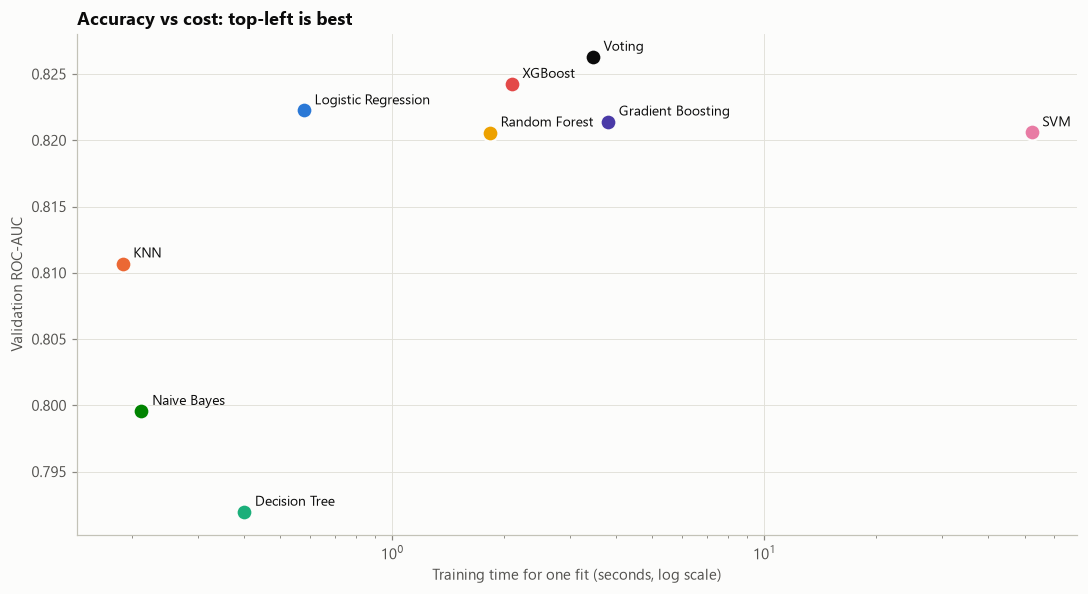

In [11]:
fig, ax = plt.subplots(figsize=(10, 5.5))
for m in models:
    r = table.loc[m]
    ax.scatter(r.fit_time_s, r.roc_auc, s=110, color=model_color(m), edgecolor=SURFACE, linewidth=1.5, zorder=3)
    ax.annotate(m, (r.fit_time_s, r.roc_auc), xytext=(7, 4), textcoords="offset points", fontsize=9, color=INK)
ax.set_xscale("log")
ax.set_xlabel("Training time for one fit (seconds, log scale)")
ax.set_ylabel("Validation ROC-AUC")
ax.set_title("Accuracy vs cost: top-left is best")
fig.tight_layout()
save_fig(fig, "06_skill_vs_time")
plt.show()

#### 📖 What this chart shows (in plain English)
The x-axis (training time) is on a log scale, so each grid step is 10 times slower.

- **Logistic regression** is in the sweet spot: **0.822 ROC-AUC in under 1 second**.
- **XGBoost** (2 s) and **Voting** (3.5 s) gain 0.002-0.004 for a few extra seconds.
- **SVM** costs **57 s per fit**, about 60 times slower than logistic regression, for a *lower* score. Kernel SVMs don't scale well to tens of thousands of rows.
- KNN, Naive Bayes and the tree are fast but noticeably weaker.

## Step 11 - Are the differences real or just noise?

> **🎓 Theory in brief**
>
> Each model's ROC-AUC is an *average of 5 folds*, so it carries noise. The fair way to compare two models is to look at their difference **fold by fold** (a *paired* comparison), because both were tested on the same people.
> 
> Ordinary t-tests are too optimistic for cross-validation, because the training sets of different folds overlap. The **Nadeau-Bengio corrected t-test** inflates the variance to account for this. A p-value above 0.05 means "we cannot tell these two models apart".
>
> *More detail: [Theory notes](../docs/THEORY_NOTES.md#13-comparing-and-selecting-models)*

**🛠️ What this code does:** Takes the top-ranked model as the reference and, for every other model, computes the fold-by-fold ROC-AUC difference, how many folds the reference wins, and the corrected t-test p-value.

In [12]:
ref = models[0]
ref_scores = results[ref].folds["test_roc_auc"].to_numpy()
k = len(folds)
n_val = np.mean([len(v) for _, v in folds]); n_tr = np.mean([len(t) for t, _ in folds])

rows = []
for m in models[1:]:
    d = ref_scores - results[m].folds["test_roc_auc"].to_numpy()
    se = np.sqrt((1 / k + n_val / n_tr) * d.var(ddof=1))
    t_stat = d.mean() / se if se > 0 else np.inf
    p = 2 * stats.t.sf(abs(t_stat), df=k - 1)
    rows.append({"model": m, "mean ROC-AUC difference": d.mean(), "folds won by " + ref: int((d > 0).sum()),
                 "corrected p-value": p, "verdict": "clearly worse" if p < 0.05 else "not distinguishable"})
diff = pd.DataFrame(rows).set_index("model")
diff.round(4).to_csv(RESULTS / "model_significance.csv")
print(f"Reference model: {ref}")
display(diff.round(4))

Reference model: Voting


,mean ROC-AUC difference,folds won by Voting,corrected p-value,verdict
model,,,,
XGBoost,0.0020,4,0.1636,not distinguishable
Logistic Regression,0.0040,5,0.0400,clearly worse
Gradient Boosting,0.0049,5,0.0864,not distinguishable
SVM,0.0057,5,0.0433,clearly worse
Random Forest,0.0057,5,0.0042,clearly worse
KNN,0.0156,5,0.0009,clearly worse
Naive Bayes,0.0267,5,0.0000,clearly worse
Decision Tree,0.0343,5,0.0006,clearly worse


**📖 What the result shows:**
With **Voting** (the top model) as the reference:

- **XGBoost** (difference 0.002, p = 0.16) and **Gradient Boosting** (0.005, p = 0.09) are **not distinguishable** from it. Their differences could easily be noise.
- **Logistic regression** (0.004 lower, p = 0.040) and **SVM** (0.006, p = 0.043) are *statistically* worse, but only just: Voting beat them on all 5 folds by a tiny margin.
- **Random forest, KNN, Naive Bayes and the decision tree** are clearly worse.

**Statistical vs practical significance:** a difference can be "real" and still too small to matter. 0.004 ROC-AUC means Voting ranks a random high-cost/low-cost pair correctly 82.6% of the time instead of 82.2%. Also remember that **Voting contains** logistic regression, random forest and XGBoost, so it is three models in one, harder to explain and slower to run.

## Step 12 - Learning curves: would more data help?

> **🎓 Theory in brief**
>
> A **learning curve** retrains a model on growing slices of the training data and plots training and validation scores.
> - If the validation score is **still rising** at full size, more data would help.
> - If both curves have **flattened and met**, the model has reached its limit with these features. Better features, not more rows, are the way forward.
>
> *More detail: [Theory notes](../docs/THEORY_NOTES.md#11-overfitting-underfitting-and-the-bias-variance-trade-off)*

**🛠️ What this code does:** Computes learning curves (10%, 25%, 50%, 75% and 100% of each training fold) for three models: the top-ranked model, the best model from a different family, and logistic regression as the simple benchmark.

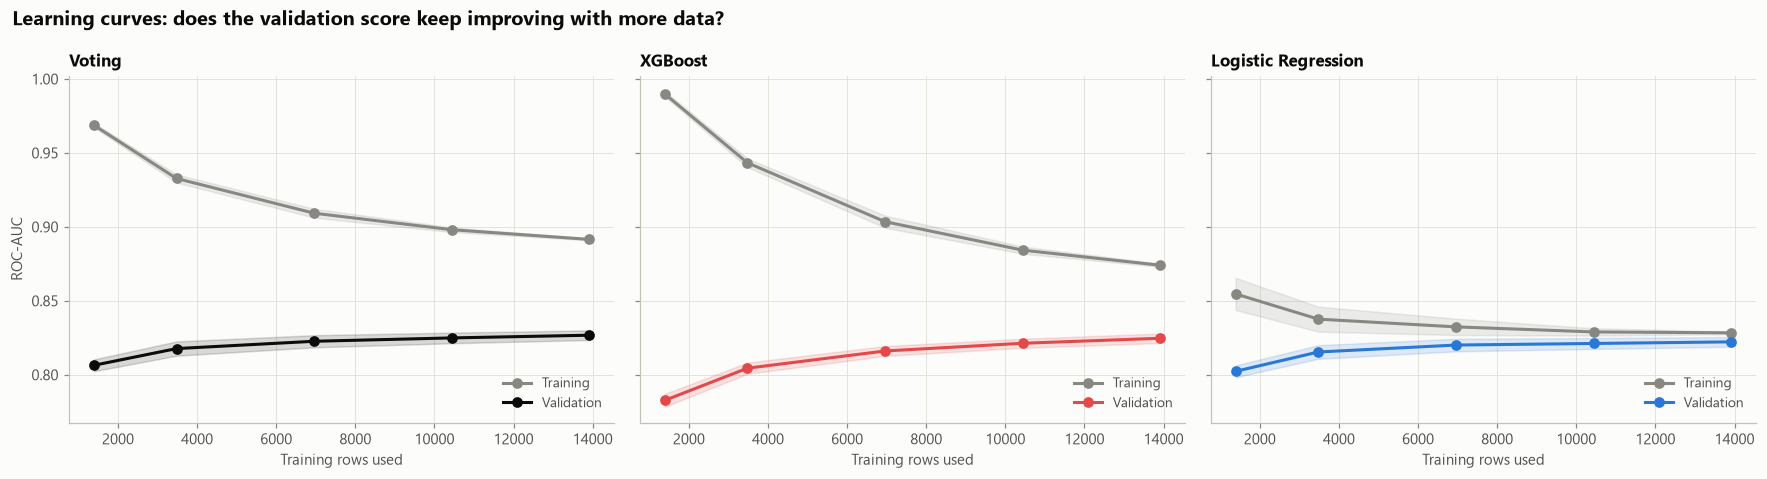

model,Logistic Regression,Voting,XGBoost
training rows,,,
1391,0.8023,0.8064,0.7827
3479,0.8154,0.8177,0.8044
6959,0.8201,0.8226,0.8161
10439,0.8212,0.8249,0.8213
13919,0.8222,0.8267,0.8247


In [13]:
families = {"Logistic Regression": "linear", "KNN": "instance", "Decision Tree": "tree", "Random Forest": "bagging",
            "SVM": "kernel", "Naive Bayes": "probabilistic", "Gradient Boosting": "boosting", "XGBoost": "boosting",
            "Voting": "ensemble"}
lc_models = [models[0]]
lc_models.append(next(m for m in models[1:] if families[m] not in {families[models[0]]} and m != "Logistic Regression"))
if "Logistic Regression" not in lc_models:
    lc_models.append("Logistic Regression")

sizes = [0.1, 0.25, 0.5, 0.75, 1.0]
fig, axes = plt.subplots(1, len(lc_models), figsize=(5.4 * len(lc_models), 4.4), sharey=True)
lc_rows = []
for ax, m in zip(axes, lc_models):
    model, sampler = build(m, best[m], pos_weight)
    n, tr_s, va_s = learning_curve(make_pipeline(preprocessor, model, sampler), X, y, cv=folds, train_sizes=sizes,
                                   scoring="roc_auc", n_jobs=5 if m in PARALLEL_FOLDS else None, shuffle=True,
                                   random_state=RANDOM_STATE)
    for s, name, color in [(tr_s, "Training", INK_MUTED), (va_s, "Validation", model_color(m))]:
        ax.plot(n, s.mean(1), marker="o", color=color, label=name)
        ax.fill_between(n, s.mean(1) - s.std(1), s.mean(1) + s.std(1), color=color, alpha=0.15)
    lc_rows += [{"model": m, "training rows": int(a), "train ROC-AUC": b, "validation ROC-AUC": c}
                for a, b, c in zip(n, tr_s.mean(1), va_s.mean(1))]
    ax.set_title(m, fontsize=11)
    ax.set_xlabel("Training rows used")
    ax.legend(loc="lower right", fontsize=9)
axes[0].set_ylabel("ROC-AUC")
fig.suptitle("Learning curves: does the validation score keep improving with more data?", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "06_learning_curves")
plt.show()
display(pd.DataFrame(lc_rows).pivot(index="training rows", columns="model", values="validation ROC-AUC").round(4))

#### 📖 What this chart shows (in plain English)
- **Logistic regression (right):** the training and validation curves have almost **met**: training 0.828, validation 0.822. Doubling the data would barely help. It has reached its limit with these features.
- **XGBoost (middle):** validation is still **rising** (0.821 → 0.825 over the last two steps), and the training curve keeps falling towards it. More data would probably help it a little.
- **Voting (left):** in between, still creeping up (0.825 → 0.827).

**Takeaway:** the flexible models are slightly data-hungry, but all three are close to the ceiling of these 37 features. To improve a lot, we would need *better information* (for example, prior-year spending or more clinical detail), not just more rows.

## Step 13 - Decision: the shortlist for tuning

**🛠️ What this code does:** Applies the selection rule and saves the shortlist to `reports/results/model_shortlist.json`:
1. Keep every model that is **not statistically distinguishable** from the top model (Step 11).
2. From those, keep the best of each **model family**, so the shortlist stays diverse.
3. Always include **logistic regression** as the simple, fully explainable benchmark.

In [14]:
contenders = [ref] + [m for m in diff.index if diff.loc[m, "verdict"] == "not distinguishable"]
shortlist, seen = [], set()
for m in contenders:                    # contenders are already in ROC-AUC order
    if families[m] not in seen:
        shortlist.append(m); seen.add(families[m])
if "Logistic Regression" not in shortlist:
    shortlist.append("Logistic Regression")

(RESULTS / "model_shortlist.json").write_text(json.dumps({
    "shortlist": shortlist,
    "variants": {m: best[m] for m in shortlist},
    "rule": "not distinguishable from the top model (Nadeau-Bengio corrected t-test, p >= 0.05), "
            "best per model family, plus logistic regression as the explainable benchmark",
    "cv_roc_auc": {m: round(float(table.loc[m, "roc_auc"]), 4) for m in shortlist},
}, indent=2))
display(table.loc[shortlist, ["variant", "roc_auc", "pr_auc", "f1", "recall", "precision", "fit_time_s"]]
        .round(3).rename(columns={**METRIC_LABELS, "fit_time_s": "Fit time (s)"}))
print("Shortlist saved:", shortlist)

,variant,ROC-AUC,PR-AUC,F1,Recall,Precision,Fit time (s)
Voting,Soft voting (LR + RF + XGB),0.826,0.568,0.552,0.703,0.455,3.460
XGBoost,"scale_pos_weight, depth 3, 600 trees",0.824,0.565,0.546,0.733,0.435,2.095
Logistic Regression,L2 + balanced,0.822,0.566,0.543,0.724,0.434,0.579


Shortlist saved: ['Voting', 'XGBoost', 'Logistic Regression']


**📖 What the result shows:**
**Shortlist for tuning in notebook 07:**

| Model | Why it is on the shortlist |
|---|---|
| **Voting** (soft: LR + RF + XGB) | Top ROC-AUC (0.826), PR-AUC and F1 |
| **XGBoost** | Not statistically distinguishable from Voting. Best single model, fast, with room to reduce overfitting |
| **Logistic Regression** | Simple, fully explainable benchmark: 0.004 behind, no overfitting, under 1 second to train |

Gradient Boosting was also "not distinguishable", but it belongs to the same *boosting* family as XGBoost, so only the better of the two (XGBoost) goes forward.

The **test set has still not been touched.** Notebook 07 tunes these three on the training data, picks the final model, chooses its threshold, and only then evaluates it once on the test set.

## Summary

**Result of the model comparison (5-fold CV, training data only):**

1. **Six models are essentially tied** at ROC-AUC 0.821-0.826: Voting, XGBoost, logistic regression, Gradient Boosting, SVM and random forest. KNN (0.811), Naive Bayes (0.800) and the decision tree (0.792) are clearly behind.
2. **Voting is the top scorer** (ROC-AUC 0.826, PR-AUC 0.568, F1 0.552), but it beats XGBoost only within noise, and logistic regression by just 0.004.
3. **Threshold metrics differ more than ranking metrics.** Recall ranges from 0.24 (KNN) to 0.76 (Naive Bayes), depending on each model's default threshold. Ranking skill is nearly the same.
4. **Overfitting:** the random forest memorises most (gap +0.112), boosting moderately (+0.05), and logistic regression barely (+0.006).
5. **Cost:** logistic regression gives 99.5% of the best score in a quarter of the time. SVM is 60 times slower for less.
6. **Learning curves:** the models are near the limit of the current features. Better information, not more rows, would be the next big step.

**Shortlist for notebook 07:** Voting, XGBoost and Logistic Regression.

**Saved results:** `reports/results/model_comparison.csv`, `model_significance.csv`, `model_shortlist.json`.

**Next:** `07_hyperparameter_tuning.ipynb` tunes the shortlist, chooses the final model and threshold, and opens the test set once for the final evaluation.